# TurboQuant KV-cache compression: LLM inference demo (Google Colab)

This notebook reproduces the core ideas of **TurboQuant** (Zandieh, Daliri, Hadian, Mirrokni, Google Research, arXiv:2504.19874)
end-to-end in pure PyTorch, on the model the paper evaluates.

1. **Theory check.** TurboQuant's measured distortion versus the paper's upper and lower bounds.
2. **Quality.** Perplexity, KL divergence and top-1 agreement versus the FP16 cache, on WikiText-2.
3. **Needle in a haystack.** Long-context retrieval with the compressed cache.
4. **Memory.** Measured KV-cache bytes and GPU memory for an 8B model.
5. **Speed.** Why fused kernels matter (e.g. vLLM).

**Why Llama-3.1-8B-Instruct?**
It is the model the paper uses for its LongBench and needle-in-a-haystack results (Table 1 and Figure 4), so the numbers here can be read next to the paper's.
An earlier version of this demo used Qwen2.5-1.5B-Instruct on a free T4. In our test runs, smaller models such as Qwen2.5 and Llama-2 lost the needle once the cache was compressed to low bit-widths.
The next cell prints Llama's attention code: Hugging Face applies RoPE to the keys *before* `past_key_values.update(...)`, so the cache always stores rotated (post-RoPE) keys.
That is the same for every model in `transformers` and for the paper's own setup, so RoPE alone does not explain the difference.
The likely cause is that Qwen2 models add a bias to `k_proj` and have a few key channels with very large values, which low-bit quantizers handle badly; Llama-3.1's keys are better behaved.
(This explanation is inferred; the Qwen runs were not kept.)

**Runtime:** `Runtime > Change runtime type > A100` (40 GB) or **L4** (24 GB). The model needs about 16 GB in FP16, so it does not fit a free T4.
It is a gated model: accept Meta's licence on its Hugging Face page, then add your token as a Colab secret named `HF_TOKEN`.

> The reference implementation stores keys and values bit-packed and dequantizes them on read. That saves memory but adds work, so it is **slower** than the FP16 cache. Production speedups need fused kernels (vLLM ships them: `--kv-cache-dtype turboquant_4bit_nc`).

**Companion reading:** the workshop guide (`docs/guide/TurboQuant_Technical_Guide_EN.md` in the repository; Spanish version `TurboQuant_Guia_Tecnica_ES.md`). Section 3 explains the algorithm, section 5 the KV-cache use case, and section 7.1 walks through this notebook section by section.

In [1]:
# Installs what Colab lacks; transformers must be v5 for the custom cache.
import importlib, subprocess, sys
def _ensure(pkg, spec):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", spec], check=True)
import transformers
if int(transformers.__version__.split(".")[0]) < 5:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-U", "transformers>=5.0,<6", "accelerate"], check=True)
    print("Upgraded transformers. Please restart the runtime (Runtime > Restart session) and run again.")
for p, s in [("datasets", "datasets"), ("matplotlib", "matplotlib"), ("pandas", "pandas"), ("seaborn", "seaborn")]:
    _ensure(p, s)
print("transformers", transformers.__version__)

transformers 5.18.0


### Where the KV cache sits in Llama's attention
The printout below shows that `apply_rotary_pos_emb` runs before `past_key_values.update(...)`: the cache receives keys that already carry RoPE.

In [2]:
import inspect
from transformers.models.llama.modeling_llama import LlamaAttention
print("Full LlamaAttention forward pass:")
print(inspect.getsource(LlamaAttention.forward))


Full LlamaAttention forward pass:
    def forward(
        self,
        hidden_states: torch.Tensor,
        position_embeddings: tuple[torch.Tensor, torch.Tensor] | None = None,
        attention_mask: torch.Tensor | None = None,
        past_key_values: Cache | None = None,
        **kwargs: Unpack[TransformersKwargs],
    ) -> tuple[torch.Tensor, torch.Tensor]:
        input_shape = hidden_states.shape[:-1]
        hidden_shape = (*input_shape, -1, self.head_dim)

        query_states = self.q_proj(hidden_states).view(hidden_shape).transpose(1, 2)
        key_states = self.k_proj(hidden_states).view(hidden_shape).transpose(1, 2)
        value_states = self.v_proj(hidden_states).view(hidden_shape).transpose(1, 2)

        cos, sin = position_embeddings
        query_states, key_states = apply_rotary_pos_emb(query_states, key_states, cos, sin)

        if past_key_values is not None:
            key_states, value_states = past_key_values.update(key_states, value_states, self.layer_id

## The TurboQuant implementation
The next cell writes `turboquant_core.py` (about 400 lines, readable). Below is the complete architectural breakdown of the vector quantization pipeline implemented in this module:

### 1. Optimal Lloyd-Max Codebooks
* `lloyd_max_codebook(d, bits)`: Calculates the mathematically optimal scalar centroids for the coordinates of a uniformly random unit vector of dimension $d$. Because these coordinates follow a scaled Beta distribution (as proved in Lemma 1 of the paper), this function uses 1D k-means to compute the optimal quantizer centroids and caches them via `@lru_cache` for speed.

### 2. Custom Coordinate-Wise Bit Packing
* `pack_bits` & `unpack_bits`: Standard PyTorch works with 8-bit bytes at minimum. To measure true physical memory footprints for non-standard bit widths (like 3-bit or 1-bit flags), these functions perform bitwise shift operations to pack smaller arbitrary-width integer codes tightly into dense `uint8` tensors.

### 3. TurboQuant Quantizers
* **Haar-Random Orthogonal Rotation (`random_rotation`)**: Applies a Householder-based QR decomposition to generate a reproducible, seed-based orthogonal matrix $\Pi$ used to spread outlier channels evenly.
* **`TurboQuant` Class**:
  * **`quantize`**: Computes the vector's Euclidean norm, normalizes it to a unit vector, rotates it using the orthogonal matrix $\Pi$, maps the coordinates to their closest Lloyd-Max centroids, and packs the bits.
  * **`dequantize`**: Unpacks the codes, maps them back to centroids, applies the inverse rotation, and scales the output back by the stored norm.
* **`MixedTurboQuant` Class**: Realizes the outlier split (e.g., 2.5-bit or 3.5-bit configurations). It dynamically identifies outlier indices (dimensions with the highest average magnitude) during calibration, and handles high-precision bits for outliers while keeping low-precision bits for standard dimensions.
* **`UniformQuant` Class**: Standard asymmetric min-max integer quantization that stores block-level scale and zero parameters for comparison.

### 4. Integration with Hugging Face (`TurboQuantCache`)
* **`TurboQuantLayer`**: Inherits from Hugging Face's `DynamicLayer`. When a sequence generates new tokens, they are initially processed in full precision. Once they exceed a specified `residual_length`, the historical keys and values are compressed on the fly and appended to a growing, compressed cache.
* **`TurboQuantCache`**: Coordinates these compressed layers to act as a drop-in replacement for standard key-value storage caches in Hugging Face generation loops.

In [3]:
%%writefile turboquant_core.py
"""
turboquant_core.py - a compact, pure-PyTorch reference implementation of TurboQuant.

Paper: Zandieh, Daliri, Hadian, Mirrokni. "TurboQuant: Online Vector Quantization with
Near-optimal Distortion Rate" (arXiv:2504.19874). Builds on QJL (arXiv:2406.03482) and
PolarQuant (arXiv:2502.02617).

What is implemented
  * Lloyd-Max codebooks for the exact coordinate distribution of a random unit vector
    (a scaled Beta distribution, Lemma 1 of the paper).
  * TurboQuant_mse  (Algorithm 1): random rotation -> per-coordinate optimal scalar quantizer.
  * TurboQuant_prod (Algorithm 2): TurboQuant_mse with b-1 bits + 1-bit QJL on the residual,
    giving an unbiased inner-product estimator.
  * Outlier-channel split ("2.5-bit" / "3.5-bit" configurations from Section 4.3).
  * Real bit-packing so memory numbers are measured, not estimated.
  * A uniform INT-b baseline with per-group fp16 scale + zero point (KIVI / HF QuantizedCache style).
  * A Hugging Face `transformers` (v5) KV-cache (`TurboQuantCache`) that stores keys/values
    compressed and dequantizes on read.

This is a readable reference, not a fused kernel: dequantization happens in PyTorch, so it
saves memory but does not speed attention up. Production speedups come from fused kernels
(e.g. vLLM `--kv-cache-dtype turboquant_*`).
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from functools import lru_cache

import numpy as np
import torch

# ----------------------------------------------------------------------------------------
# 1. Codebooks: Lloyd-Max for the coordinate distribution of a uniformly random unit vector
# ----------------------------------------------------------------------------------------


@lru_cache(maxsize=None)
def lloyd_max_codebook(d: int, bits: int, iters: int = 400, grid: int = 200_001) -> np.ndarray:
    """Optimal scalar quantizer (2**bits centroids) for f(x) ~ (1 - x^2)^((d-3)/2) on [-1, 1].

    This solves the continuous 1-D k-means problem of Eq. (4) numerically. Results are cached.
    """
    k = 2 ** bits
    x = np.linspace(-1.0, 1.0, grid)[1:-1]
    logf = 0.5 * (d - 3) * np.log1p(-x * x) if d > 3 else np.zeros_like(x)
    f = np.exp(logf - logf.max())
    f /= f.sum()
    # initialise at quantiles
    cdf = np.cumsum(f)
    c = np.interp((np.arange(k) + 0.5) / k, cdf, x)
    for _ in range(iters):
        b = 0.5 * (c[1:] + c[:-1])
        cell = np.searchsorted(b, x)
        w = np.bincount(cell, weights=f, minlength=k)
        m = np.bincount(cell, weights=f * x, minlength=k)
        c_new = np.where(w > 0, m / np.maximum(w, 1e-300), c)
        if np.max(np.abs(c_new - c)) < 1e-12:
            c = c_new
            break
        c = c_new
    return c.astype(np.float64)


def codebook_mse_cost(d: int, bits: int) -> float:
    """d * C(f_X, b): expected ||x - Q^-1(Q(x))||^2 for a unit vector (Theorem 1)."""
    c = lloyd_max_codebook(d, bits)
    x = np.linspace(-1.0, 1.0, 200_001)[1:-1]
    logf = 0.5 * (d - 3) * np.log1p(-x * x)
    f = np.exp(logf - logf.max()); f /= f.sum()
    b = 0.5 * (c[1:] + c[:-1])
    err = (x - c[np.searchsorted(b, x)]) ** 2
    return float(d * (err * f).sum())


# ----------------------------------------------------------------------------------------
# 2. Bit packing (any bit-width; exactly bits*d/8 bytes per vector)
# ----------------------------------------------------------------------------------------


def pack_bits(idx: torch.Tensor, bits: int) -> torch.Tensor:
    """Pack integer codes in [0, 2**bits) of shape [..., d] into uint8 of shape [..., bits*d/8]."""
    d = idx.shape[-1]
    assert d % 8 == 0, "last dim must be a multiple of 8"
    idx = idx.to(torch.uint8)
    shifts = torch.arange(bits, device=idx.device, dtype=torch.uint8)
    planes = (idx.unsqueeze(-2) >> shifts.view(-1, 1)) & 1            # [..., bits, d]
    planes = planes.reshape(*idx.shape[:-1], bits, d // 8, 8)
    weights = (1 << torch.arange(8, device=idx.device, dtype=torch.uint8))
    packed = (planes * weights).sum(-1, dtype=torch.uint8)             # [..., bits, d/8]
    return packed.reshape(*idx.shape[:-1], bits * d // 8)


_LUT = {}


def _bit_lut(device):
    if device not in _LUT:
        _LUT[device] = ((torch.arange(256, device=device).unsqueeze(1) >> torch.arange(8, device=device)) & 1).to(torch.uint8)
    return _LUT[device]


def unpack_bits(packed: torch.Tensor, bits: int, d: int) -> torch.Tensor:
    """Inverse of pack_bits -> int64 codes of shape [..., d] (one table lookup per byte)."""
    planes = _bit_lut(packed.device)[packed.long()]                      # [..., bits*d/8, 8]
    planes = planes.reshape(*packed.shape[:-1], bits, d)
    codes = planes[..., 0, :].clone()
    for j in range(1, bits):
        codes |= planes[..., j, :] << j
    return codes.long()


# ----------------------------------------------------------------------------------------
# 3. TurboQuant quantizers
# ----------------------------------------------------------------------------------------


def random_rotation(d: int, seed: int, device=None) -> torch.Tensor:
    """Haar-random orthogonal matrix via QR of a Gaussian matrix (Section 3.1)."""
    g = torch.Generator().manual_seed(seed)
    a = torch.randn(d, d, generator=g, dtype=torch.float64)
    q, r = torch.linalg.qr(a)
    q = q * torch.sign(torch.diagonal(r)).unsqueeze(0)
    return q.to(device=device, dtype=torch.float32)


@dataclass
class Compressed:
    """A batch of compressed vectors. Every field is a tensor with the same leading shape."""
    idx: torch.Tensor                    # packed MSE codes (uint8)
    norm: torch.Tensor                   # ||x|| in fp16
    qjl: torch.Tensor | None = None      # packed QJL sign bits (uint8), prod mode only
    gamma: torch.Tensor | None = None    # ||residual|| in fp16, prod mode only

    def nbytes(self) -> int:
        return sum(t.numel() * t.element_size() for t in (self.idx, self.norm, self.qjl, self.gamma) if t is not None)

    def cat(self, other: "Compressed", dim: int) -> "Compressed":
        def c(a, b):
            return None if a is None else torch.cat([a, b], dim=dim)
        return Compressed(c(self.idx, other.idx), c(self.norm, other.norm), c(self.qjl, other.qjl), c(self.gamma, other.gamma))


class TurboQuant:
    """TurboQuant for d-dimensional vectors (arbitrary norm; the norm is stored in fp16).

    mode="mse"  -> Algorithm 1, `bits` bits per coordinate.
    mode="prod" -> Algorithm 2, (bits-1)-bit MSE stage + 1-bit QJL on the residual (unbiased <y, x>).
    renorm=True -> rescale the reconstruction so its norm equals the stored norm (cheap "norm
                   correction", similar in spirit to vLLM's *_nc variants).
    """

    def __init__(self, d: int, bits: int, mode: str = "mse", seed: int = 0, device=None, renorm: bool = False):
        assert mode in ("mse", "prod")
        assert d % 8 == 0
        self.d, self.bits, self.mode, self.renorm = d, bits, mode, renorm
        self.mse_bits = bits if mode == "mse" else bits - 1
        assert self.mse_bits >= 0
        self.device = device
        self.Pi = random_rotation(d, seed, device)                      # rotation (d x d)
        if self.mse_bits > 0:
            c = torch.tensor(lloyd_max_codebook(d, self.mse_bits), dtype=torch.float32, device=device)
            self.centroids = c
            self.boundaries = 0.5 * (c[1:] + c[:-1])
        if mode == "prod":
            g = torch.Generator().manual_seed(seed + 7919)
            self.S = torch.randn(d, d, generator=g).to(device)          # QJL projection
        self.bits_per_vector = bits * d + 16 + (16 if mode == "prod" else 0)

    def to(self, device):
        self.device = device
        for name in ("Pi", "centroids", "boundaries", "S"):
            if hasattr(self, name):
                setattr(self, name, getattr(self, name).to(device))
        return self

    # --- Algorithm 1 -------------------------------------------------------------------
    def _mse_codes(self, u: torch.Tensor) -> torch.Tensor:
        y = u @ self.Pi.T
        return torch.bucketize(y, self.boundaries)

    def _mse_decode(self, codes: torch.Tensor) -> torch.Tensor:
        return self.centroids[codes] @ self.Pi

    # --- public API -------------------------------------------------------------------
    @torch.no_grad()
    def quantize(self, x: torch.Tensor) -> Compressed:
        x = x.float()
        norm = x.norm(dim=-1, keepdim=True)
        u = x / norm.clamp_min(1e-12)
        if self.mse_bits > 0:
            codes = self._mse_codes(u)
            idx = pack_bits(codes, self.mse_bits)
            u_mse = self._mse_decode(codes)
        else:
            idx = torch.zeros(*x.shape[:-1], 0, dtype=torch.uint8, device=x.device)
            u_mse = torch.zeros_like(u)
        if self.mode == "mse":
            return Compressed(idx, norm.squeeze(-1).half())
        r = u - u_mse                                                    # residual
        signs = (r @ self.S.T) >= 0
        return Compressed(idx, norm.squeeze(-1).half(), pack_bits(signs, 1), r.norm(dim=-1).half())

    @torch.no_grad()
    def dequantize(self, c: Compressed, dtype=torch.float32) -> torch.Tensor:
        if self.mse_bits > 0:
            u = self._mse_decode(unpack_bits(c.idx, self.mse_bits, self.d))
        else:
            u = torch.zeros(*c.norm.shape, self.d, device=c.norm.device)
        if self.mode == "prod":
            z = unpack_bits(c.qjl, 1, self.d).float() * 2 - 1              # {-1,+1}
            u = u + (math.sqrt(math.pi / 2) / self.d) * c.gamma.float().unsqueeze(-1) * (z @ self.S)
        if self.renorm:
            u = u / u.norm(dim=-1, keepdim=True).clamp_min(1e-12)
        return (u * c.norm.float().unsqueeze(-1)).to(dtype)

    def roundtrip(self, x: torch.Tensor) -> torch.Tensor:
        return self.dequantize(self.quantize(x), x.dtype)


class MixedTurboQuant:
    """Outlier split from Section 4.3: `n_out` outlier channels get `bits_hi`, the rest `bits_lo`.

    Example (paper): head_dim 128, 32 outliers @3 bits + 96 @2 bits = 2.5 bits/channel.
    Outlier channels are picked by `calibrate` (largest mean |x| on a sample, e.g. the prefill).
    """

    def __init__(self, d: int, n_out: int, bits_hi: int, bits_lo: int, mode="mse", seed=0, device=None, renorm=False):
        self.d, self.n_out = d, n_out
        self.hi = TurboQuant(n_out, bits_hi, mode, seed, device, renorm)
        self.lo = TurboQuant(d - n_out, bits_lo, mode, seed + 1, device, renorm)
        self.out_idx = torch.arange(n_out, device=device)
        self.in_idx = torch.arange(n_out, d, device=device)
        self.bits = (n_out * bits_hi + (d - n_out) * bits_lo) / d
        self.calibrated = False

    def calibrate(self, sample: torch.Tensor):
        score = sample.float().abs().reshape(-1, self.d).mean(0)
        order = torch.argsort(score, descending=True)
        self.out_idx, self.in_idx = order[: self.n_out].sort().values, order[self.n_out:].sort().values
        self.calibrated = True

    def to(self, device):
        self.hi.to(device); self.lo.to(device)
        self.out_idx, self.in_idx = self.out_idx.to(device), self.in_idx.to(device)
        return self

    def quantize(self, x):
        if not self.calibrated:
            self.calibrate(x)
        return (self.hi.quantize(x[..., self.out_idx]), self.lo.quantize(x[..., self.in_idx]))

    def dequantize(self, c, dtype=torch.float32):
        a, b = c
        lead = a.norm.shape
        out = torch.empty(*lead, self.d, device=a.norm.device, dtype=dtype)
        out[..., self.out_idx] = self.hi.dequantize(a, dtype)
        out[..., self.in_idx] = self.lo.dequantize(b, dtype)
        return out

    def roundtrip(self, x):
        return self.dequantize(self.quantize(x), x.dtype)


class UniformQuant:
    """Baseline: asymmetric min-max INT-b per group of `group` channels, fp16 scale + zero per group.

    Effective bits/channel = bits + 32/group (the "memory overhead" TurboQuant removes).
    """

    def __init__(self, d: int, bits: int, group: int = 32):
        assert d % group == 0
        self.d, self.bits, self.group = d, bits, group
        self.bits_per_vector = bits * d + 32 * (d // group)

    def to(self, device):
        return self

    @torch.no_grad()
    def quantize(self, x):
        g = x.float().reshape(*x.shape[:-1], self.d // self.group, self.group)
        lo, hi = g.amin(-1, keepdim=True), g.amax(-1, keepdim=True)
        scale = ((hi - lo) / (2 ** self.bits - 1)).clamp_min(1e-8)
        q = torch.round((g - lo) / scale).clamp(0, 2 ** self.bits - 1)
        packed = pack_bits(q.reshape(*x.shape[:-1], self.d).long(), self.bits)
        return (packed, scale.half(), lo.half())

    @torch.no_grad()
    def dequantize(self, c, dtype=torch.float32):
        packed, scale, lo = c
        q = unpack_bits(packed, self.bits, self.d).float()
        q = q.reshape(*q.shape[:-1], self.d // self.group, self.group)
        return (q * scale.float() + lo.float()).reshape(*q.shape[:-2], self.d).to(dtype)

    def roundtrip(self, x):
        return self.dequantize(self.quantize(x), x.dtype)


def nbytes(c) -> int:
    """Bytes used by any compressed object returned by the quantizers above."""
    if isinstance(c, Compressed):
        return c.nbytes()
    if isinstance(c, (tuple, list)):
        return sum(nbytes(t) for t in c)
    if isinstance(c, torch.Tensor):
        return c.numel() * c.element_size()
    return 0


def cat_compressed(a, b, dim):
    if isinstance(a, Compressed):
        return a.cat(b, dim)
    if isinstance(a, (tuple, list)):
        return type(a)(cat_compressed(x, y, dim) for x, y in zip(a, b))
    return torch.cat([a, b], dim=dim)


# ----------------------------------------------------------------------------------------
# 4. Hugging Face transformers (v5) KV cache
# ----------------------------------------------------------------------------------------
try:
    from transformers.cache_utils import Cache, DynamicLayer

    class TurboQuantLayer(DynamicLayer):
        """One attention layer's cache: keys/values stored compressed, the last
        `residual_length` tokens kept in full precision (0 = quantize everything, as in the paper)."""

        def __init__(self, k_quant, v_quant, residual_length: int = 0):
            super().__init__()
            self.kq, self.vq = k_quant, v_quant
            self.residual_length = residual_length
            self.ck = self.cv = None          # compressed storage, token axis = -2 of the original
            self.cumulative_length = 0

        def lazy_initialization(self, key_states, value_states):
            super().lazy_initialization(key_states, value_states)
            for q in (self.kq, self.vq):
                q.to(key_states.device)
                if isinstance(q, MixedTurboQuant) and not q.calibrated:
                    q.calibrate(key_states if q is self.kq else value_states)

        def _append(self, k, v):
            ck, cv = self.kq.quantize(k), self.vq.quantize(v)
            if self.ck is None:
                self.ck, self.cv = ck, cv
            else:  # leading dims [B, H, T, D] -> token axis is 2 for compressed Compressed structures
                self.ck, self.cv = cat_compressed(self.ck, ck, 2), cat_compressed(self.cv, cv, 2)

        def update(self, key_states, value_states, *args, **kwargs):
            if not self.is_initialized:
                self.lazy_initialization(key_states, value_states)
            self.cumulative_length += key_states.shape[-2]
            dt = key_states.dtype

            # Step 1: Append incoming tokens to full-precision temporary buffers
            self.keys = torch.cat([self.keys, key_states], dim=-2)
            self.values = torch.cat([self.values, value_states], dim=-2)

            # Step 2: Push overflow tokens out of full-precision buffers into compressed containers
            overflow = self.keys.shape[-2] - self.residual_length
            if overflow > 0:
                self._append(self.keys[..., :overflow, :], self.values[..., :overflow, :])
                self.keys = self.keys[..., overflow:, :].contiguous()
                self.values = self.values[..., overflow:, :].contiguous()

            # Step 3: Dequantize the history and build cleanly aligned, non-overlapping outputs
            parts_k, parts_v = [], []
            if self.ck is not None:
                parts_k.append(self.kq.dequantize(self.ck, dt))
                parts_v.append(self.vq.dequantize(self.cv, dt))

            k_out = torch.cat(parts_k + [self.keys], dim=-2)
            v_out = torch.cat(parts_v + [self.values], dim=-2)
            return k_out, v_out

        def get_seq_length(self) -> int:
            return self.cumulative_length

        def reset(self):
            self.ck = self.cv = None
            self.cumulative_length = 0
            super().reset()

        def nbytes(self) -> int:
            fp = 0 if self.keys is None else self.keys.numel() * self.keys.element_size() * 2
            return fp + nbytes(self.ck) + nbytes(self.cv)

    class TurboQuantCache(Cache):
        """Drop-in KV cache for HF `generate`/forward.

        make_k / make_v: callables (layer_idx, head_dim) -> quantizer (TurboQuant, MixedTurboQuant,
        UniformQuant). Each layer gets its own random rotation via the seed.
        """

        def __init__(self, config, make_k, make_v, residual_length: int = 0):
            cfg = config.get_text_config(decoder=True) if hasattr(config, "get_text_config") else config
            hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
            layers = [TurboQuantLayer(make_k(i, hd), make_v(i, hd), residual_length) for i in range(cfg.num_hidden_layers)]
            super().__init__(layers=layers)

        def nbytes(self) -> int:
            return sum(l.nbytes() for l in self.layers)

    def fp16_cache_nbytes(cache) -> int:
        """Bytes of a regular DynamicCache."""
        return sum(l.keys.numel() * l.keys.element_size() + l.values.numel() * l.values.element_size()
                   for l in cache.layers if l.keys is not None)

except ImportError:
    pass


# ----------------------------------------------------------------------------------------
# 5. Convenience factories
# ----------------------------------------------------------------------------------------

def tq_factory(bits, mode="mse", renorm=False, seed=0):
    def make(layer_idx, d):
        return TurboQuant(d, bits, mode=mode, seed=seed + 1000 * layer_idx, renorm=renorm)
    return make


def mixed_factory(n_out_frac, bits_hi, bits_lo, mode="mse", renorm=False, seed=0):
    def make(layer_idx, d):
        n_out = int(round(d * n_out_frac / 8)) * 8
        return MixedTurboQuant(d, n_out, bits_hi, bits_lo, mode=mode, seed=seed + 1000 * layer_idx, renorm=renorm)
    return make


def uniform_factory(bits, group=32):
    def make(layer_idx, d):
        return UniformQuant(d, bits, group)
    return make

Writing turboquant_core.py


In [4]:
import math, time, gc, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
import importlib, turboquant_core as tq
importlib.reload(tq)
from turboquant_core import (TurboQuant, MixedTurboQuant, UniformQuant, TurboQuantCache, fp16_cache_nbytes,
                             tq_factory, mixed_factory, uniform_factory, codebook_mse_cost, lloyd_max_codebook)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
torch.manual_seed(0); np.random.seed(0); random.seed(0)

device: cuda NVIDIA A100-SXM4-40GB


## 1. Theory check: distortion versus the paper's bounds
For unit vectors, Theorem 1 says `D_mse <= (sqrt(3)*pi/2) * 4^-b` and Theorem 3 says no quantizer can beat `4^-b`.
The paper reports `D_mse ≈ 0.36, 0.117, 0.03, 0.009` for b = 1..4.

### Code Explanation:
1. **Data Generation**: It creates random normal unit vectors $x$ and $y$ of dimension $d = 128$ in PyTorch. The vector $y$ (representing queries) is correlated with $x$ (representing keys) so their inner products are non-trivial.
2. **Theoretical Validation Loop**: For bit widths $b \in [1, 5]$, it quantizes and dequantizes (roundtrip) the vectors using both the MSE-optimized variant (`TurboQuant_mse`) and the unbiased variant (`TurboQuant_prod`). It measures actual Mean Squared Error (MSE), compares it against the paper's theoretical bounds, and tracks the bias and error of the reconstructed inner products.
3. **Visualizations** (using `matplotlib`):
   - **Subplot 1**: Plots the measured MSE against the information-theoretic lower and upper bounds, showing that the empirical distortion falls perfectly within the predicted limits.
   - **Subplot 2**: Plots a histogram of the error in inner products at 2 bits, demonstrating how the standard MSE variant is biased (shifted left) while the product variant (`TurboQuant_prod`) remains centered and unbiased.
   - **Subplot 3**: Illustrates that the coordinates of randomly rotated unit vectors converge to a standard normal distribution, allowing a single precomputed Lloyd-Max codebook to work universally.

,bits,mse_measured,mse_theory,lower_bound,upper_bound,ip_bias_mse,ip_bias_prod,ip_err_mse_x_d,ip_err_prod_x_d
0,1,0.3606,0.3609,0.2500,0.6802,-0.3611,0.0024,6.2502,1.2248
1,2,0.1158,0.1160,0.0625,0.1700,-0.1157,0.0014,0.7448,0.5254
2,3,0.0339,0.0340,0.0156,0.0425,-0.0340,0.0002,0.1015,0.1774
3,4,0.0093,0.0093,0.0039,0.0106,-0.0091,0.0003,0.0185,0.0519
4,5,0.0024,0.0025,0.0010,0.0027,-0.0025,0.0000,0.0044,0.0144


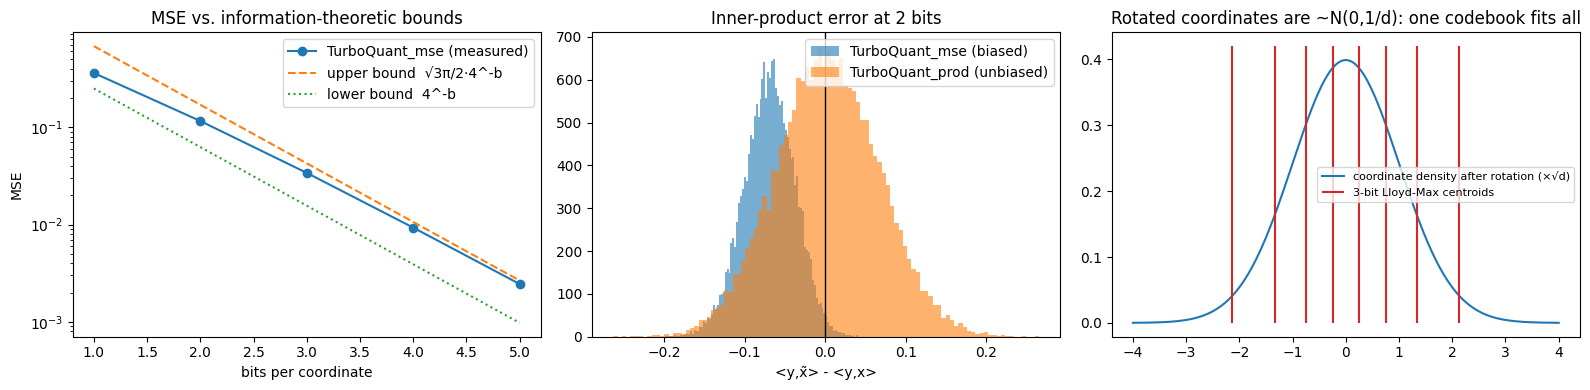

In [5]:
d = 128   # a typical attention head dimension
N = 20000
x = torch.randn(N, d, device=DEVICE); x = x / x.norm(dim=1, keepdim=True)
y = torch.randn(N, d, device=DEVICE); y = y / y.norm(dim=1, keepdim=True)
y = (0.6 * x + 0.8 * y)  # queries correlated with the data, so inner products are not ~0
rows = []
for b in range(1, 6):
    q_mse = TurboQuant(d, b, "mse", seed=1, device=DEVICE)
    q_prod = TurboQuant(d, b, "prod", seed=1, device=DEVICE)
    xm, xp = q_mse.roundtrip(x), q_prod.roundtrip(x)
    ip, ipm, ipp = (y * x).sum(1), (y * xm).sum(1), (y * xp).sum(1)
    rows.append(dict(bits=b,
                     mse_measured=((x - xm) ** 2).sum(1).mean().item(),
                     mse_theory=codebook_mse_cost(d, b),
                     lower_bound=4.0 ** -b,
                     upper_bound=math.sqrt(3) * math.pi / 2 * 4.0 ** -b,
                     ip_bias_mse=((ipm - ip).mean() / ip.mean()).item(),
                     ip_bias_prod=((ipp - ip).mean() / ip.mean()).item(),
                     ip_err_mse_x_d=(((ipm - ip) ** 2).mean() * d).item(),
                     ip_err_prod_x_d=(((ipp - ip) ** 2).mean() * d).item()))
theory = pd.DataFrame(rows)
display(theory.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].semilogy(theory.bits, theory.mse_measured, "o-", label="TurboQuant_mse (measured)")
ax[0].semilogy(theory.bits, theory.upper_bound, "--", label="upper bound  √3π/2·4^-b")
ax[0].semilogy(theory.bits, theory.lower_bound, ":", label="lower bound  4^-b")
ax[0].set(xlabel="bits per coordinate", ylabel="MSE", title="MSE vs. information-theoretic bounds"); ax[0].legend()
q1m, q1p = TurboQuant(d, 2, "mse", seed=3, device=DEVICE), TurboQuant(d, 2, "prod", seed=3, device=DEVICE)
ax[1].hist(((y * q1m.roundtrip(x)).sum(1) - (y * x).sum(1)).cpu(), 100, alpha=.6, label="TurboQuant_mse (biased)")
ax[1].hist(((y * q1p.roundtrip(x)).sum(1) - (y * x).sum(1)).cpu(), 100, alpha=.6, label="TurboQuant_prod (unbiased)")
ax[1].axvline(0, c="k", lw=1); ax[1].set(title="Inner-product error at 2 bits", xlabel="<y,x̃> - <y,x>"); ax[1].legend()
c = lloyd_max_codebook(d, 3) * math.sqrt(d)
grid = np.linspace(-4, 4, 400)
ax[2].plot(grid, np.exp(-grid ** 2 / 2) / math.sqrt(2 * math.pi), label="coordinate density after rotation (×√d)")
ax[2].vlines(c, 0, 0.42, colors="C3", label="3-bit Lloyd-Max centroids")
ax[2].set(title="Rotated coordinates are ~N(0,1/d): one codebook fits all"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Load a model
We use `meta-llama/Llama-3.1-8B-Instruct` (32 layers, 8 KV heads, head_dim 128), which is the exact model evaluated in the original paper.
Head dim 128 lets us use exactly the paper's outlier split: 32 channels at 3 bits + 96 at 2 bits, which the paper calls **2.5 bits**. (The codes alone are 2.25 bits/channel; with the two fp16 norms the measured cost is exactly 2.5. Likewise the 3.5-bit split, 64 @4b + 64 @3b, measures 3.75 with norms. The `bits_per_channel` column below is always measured from the packed tensors.)

### Explanation of the Loading and Setup Steps:
1. **Model & Tokenizer Loading**: We use Hugging Face's `AutoTokenizer` and `AutoModelForCausalLM` to load the 8B model. (Requires HF Token authentication).
2. **Configuration Dictionary (`CONFIGS`)**: We register all KV-cache evaluation setups:
   - **Uncompressed (Baseline)**: Normal FP16 cache representation.
   - **TurboQuant ($b$-bit)**: Standard MSE quantization using `tq_factory` for 4, 3, and 2 bits.
   - **TurboQuant Outlier Splits (3.5-bit & 2.5-bit)**: Mixed-precision layouts where standard/outlier dimensions are calibrated separately.
   - **TurboQuant_prod**: Evaluates unbiased inner products using 2-bit MSE + 1-bit QJL residuals.
   - **Uniform INT Baseline**: Standard uniform integer quantization with per-group scales and zero points to serve as a classic benchmark.
3. **Helper Functions**: Defines functions to instantiate caches, calculate actual KV-cache footprint in bytes, and measure the effective bits per channel dynamically.

In [6]:
# =====================================================================
# Model Setup and Quantization Configuration Definitions
# =====================================================================
import os
from transformers import AutoModelForCausalLM, AutoTokenizer, DynamicCache
import torch

try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass  # Allow fallback to standard huggingface-cli login if secret is missing

# Using Llama-3.1-8B-Instruct as used in the original paper.
# Note: This is a gated model. You must accept the agreement on Hugging Face and provide an HF_TOKEN.
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct" if DEVICE == "cuda" else "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

# 1. Load Tokenizer and Base Model in half/full precision depending on Hardware
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, attn_implementation="sdpa").to(DEVICE).eval()
cfg = model.config
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
print(MODEL_ID, "| layers", cfg.num_hidden_layers, "| kv heads", cfg.num_key_value_heads, "| head_dim", HEAD_DIM)

# 2. Define configurations to map names to respective quantizer factories
CONFIGS = {
    "Uncompressed cache (baseline)":            None,
    "TurboQuant 4-bit":                 (tq_factory(4), tq_factory(4)),
    "TurboQuant 3.5-bit (outlier split)": (mixed_factory(0.5, 4, 3), mixed_factory(0.5, 4, 3)),
    "TurboQuant 3-bit":                 (tq_factory(3), tq_factory(3)),
    "TurboQuant 2.5-bit (outlier split)": (mixed_factory(0.25, 3, 2), mixed_factory(0.25, 3, 2)),
    "TurboQuant 2-bit":                 (tq_factory(2), tq_factory(2)),
    "TurboQuant_prod 3-bit keys (MSE 2b + QJL 1b)": (tq_factory(3, "prod"), tq_factory(3)),
    "INT4 + scale/zero per 32 ch":      (uniform_factory(4), uniform_factory(4)),
    "INT3 + scale/zero per 32 ch":      (uniform_factory(3), uniform_factory(3)),
    "INT2 + scale/zero per 32 ch":      (uniform_factory(2), uniform_factory(2)),
}

# 3. Dynamic Cache Factories and Metric Utilities
def make_cache(name, residual_length=0):
    spec = CONFIGS[name]
    if spec is None:
        return DynamicCache(config=cfg)
    return TurboQuantCache(cfg, spec[0], spec[1], residual_length=residual_length)

def cache_nbytes(cache):
    return cache.nbytes() if isinstance(cache, TurboQuantCache) else fp16_cache_nbytes(cache)

def bits_per_channel(cache, n_tokens):
    n_vec = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * n_tokens
    return 8 * cache_nbytes(cache) / (n_vec * HEAD_DIM)


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

meta-llama/Llama-3.1-8B-Instruct | layers 32 | kv heads 8 | head_dim 128


## 3. Quality: perplexity and agreement with the FP16 model
Text is fed in chunks of 128 tokens. Each chunk attends exactly to itself and to the **compressed** cache of everything before it, which mimics streaming generation where every past token lives in the quantized cache.
The text is the WikiText-2 test set. If it cannot be downloaded, the cell falls back to a repeated sentence: perplexity is then close to 1 for every configuration and only the KL and top-1 columns are meaningful.
Metrics against the FP16 run: perplexity, mean KL(FP16 ‖ quantized) of the next-token distribution, and top-1 agreement.

### Explanation of the Evaluation Metrics and Setup:
1. **Data Stream Simulation**: Instead of loading the entire sequence at once, we feed text in successive chunks of size `CHUNK = 128`. This enforces realistic autoregressive attention where historical context relies purely on decoded/dequantized KV tensors.
2. **Perplexity (PPL)**: Measures how well the compressed cache predicts the ground-truth sequence. A large jump in perplexity indicates information loss in the quantized keys/values.
3. **Kullback-Leibler (KL) Divergence**: Evaluates the statistical distance between the uncompressed next-token probability distribution (baseline) and the quantized model's distribution. Lower is better.
4. **Top-1 Agreement**: Represents the exact match rate of the highest-probability token predicted by the baseline vs. the quantized variant, showing how quantization impacts immediate greedy decisions.

In [7]:
# =====================================================================
# Quality Evaluation: Perplexity, KL Divergence, and Token Agreement
# =====================================================================
from datasets import load_dataset
import importlib
import gc, time, math
import torch
import pandas as pd
import turboquant_core as tq

# Force reload the corrected turboquant_core to ensure quality metrics use our fixes
importlib.reload(tq)
from turboquant_core import (
    TurboQuant, MixedTurboQuant, UniformQuant, TurboQuantCache, fp16_cache_nbytes,
    tq_factory, mixed_factory, uniform_factory
)

# Re-bind configurations to use reloaded factories
CONFIGS = {
    "Uncompressed cache (baseline)":            None,
    "TurboQuant 4-bit":                 (tq_factory(4), tq_factory(4)),
    "TurboQuant 3.5-bit (outlier split)": (mixed_factory(0.5, 4, 3), mixed_factory(0.5, 4, 3)),
    "TurboQuant 3-bit":                 (tq_factory(3), tq_factory(3)),
    "TurboQuant 2.5-bit (outlier split)": (mixed_factory(0.25, 3, 2), mixed_factory(0.25, 3, 2)),
    "TurboQuant 2-bit":                 (tq_factory(2), tq_factory(2)),
    "TurboQuant_prod 3-bit keys (MSE 2b + QJL 1b)": (tq_factory(3, "prod"), tq_factory(3)),
    "INT4 + scale/zero per 32 ch":      (uniform_factory(4), uniform_factory(4)),
    "INT3 + scale/zero per 32 ch":      (uniform_factory(3), uniform_factory(3)),
    "INT2 + scale/zero per 32 ch":      (uniform_factory(2), uniform_factory(2)),
}

try:
    wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")   # the bare "wikitext" id no longer resolves
    text = "\n".join(t for t in wiki["text"] if t.strip())
except Exception as e:
    print("wikitext unavailable, using a built-in passage:", e)
    text = ("The history of computing is a story of compression. " * 400)

N_TOK = 2048 if DEVICE == "cuda" else 512
CHUNK = 128
ids = tok(text, return_tensors="pt").input_ids[:, :N_TOK].to(DEVICE)

@torch.no_grad()
def chunked_logits(cache_name):
    cache = make_cache(cache_name)
    out = []
    for s in range(0, ids.shape[1], CHUNK):
        out.append(model(ids[:, s:s + CHUNK], past_key_values=cache, use_cache=True).logits.float())
    return torch.cat(out, 1), cache

ref_logits, ref_cache = chunked_logits("Uncompressed cache (baseline)")
ref_logp = torch.log_softmax(ref_logits[0, :-1], -1)
targets = ids[0, 1:]
BASE_BITS = bits_per_channel(ref_cache, ids.shape[1])
results = []

for name in CONFIGS:
    t0 = time.time()
    logits, cache = (ref_logits, ref_cache) if CONFIGS[name] is None else chunked_logits(name)
    logp = torch.log_softmax(logits[0, :-1], -1)

    nll = -logp.gather(-1, targets[:, None]).mean().item()
    kl = (ref_logp.exp() * (ref_logp - logp)).sum(-1).mean().item()
    agree = (logp.argmax(-1) == ref_logp.argmax(-1)).float().mean().item()

    results.append(dict(
        config=name,
        bits_per_channel=round(bits_per_channel(cache, ids.shape[1]), 3),
        compression=round(BASE_BITS / bits_per_channel(cache, ids.shape[1]), 2),
        perplexity=round(math.exp(nll), 3),
        KL_vs_baseline=round(kl, 5),
        top1_agree=round(agree, 4),
        kv_MB=round(cache_nbytes(cache) / 2 ** 20, 2)
    ))
    del cache; gc.collect()

quality = pd.DataFrame(results)
display(quality)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (288937 > 131072). Running this sequence through the model will result in indexing errors


,config,bits_per_channel,compression,perplexity,KL_vs_baseline,top1_agree,kv_MB
0,Uncompressed cache (baseline),16.000,1.00,5.707,0.00000,1.0000,256.0
1,TurboQuant 4-bit,4.125,3.88,5.806,0.01404,0.9590,66.0
2,TurboQuant 3.5-bit (outlier split),3.750,4.27,5.856,0.02404,0.9345,60.0
3,TurboQuant 3-bit,3.125,5.12,6.102,0.05958,0.9067,50.0
4,TurboQuant 2.5-bit (outlier split),2.500,6.40,7.382,0.24560,0.8134,40.0
5,TurboQuant 2-bit,2.125,7.53,9.360,0.47468,0.7411,34.0
6,TurboQuant_prod 3-bit keys (MSE 2b + QJL 1b),3.188,5.02,9.905,0.53260,0.7176,51.0
7,INT4 + scale/zero per 32 ch,5.000,3.20,5.779,0.01245,0.9619,80.0
8,INT3 + scale/zero per 32 ch,4.000,4.00,6.139,0.06940,0.9023,64.0
9,INT2 + scale/zero per 32 ch,3.000,5.33,17.201,1.11709,0.5979,48.0


### Explanation of the Visualization (Perplexity vs. Memory & Divergence):
1. **Subplots Setup**: The code initializes a 1x2 subplot grid showing two crucial memory-vs-quality curves side-by-side.
2. **Color Coding**: Configurations are systematically color-coded to visually distinguish approaches:
   - **Blue (`C0`)** represents **TurboQuant** configurations.
   - **Red (`C3`)** represents the **Uniform INT** baselines.
   - **Black (`k`)** represents the uncompressed **FP16 baseline**.
3. **Left Plot (Perplexity vs. Effective Bits)**: Compares the compression rate (effective bits per channel) against language model perplexity. Outlier splits (indicated with `*`) show high compression with minimal perplexity rise.
4. **Right Plot (KL Divergence vs. Effective Bits)**: Uses a logarithmic y-axis to represent the exact probability distribution distance (KL divergence) from the FP16 target, detailing how closely the soft probability space of token predictions is preserved.

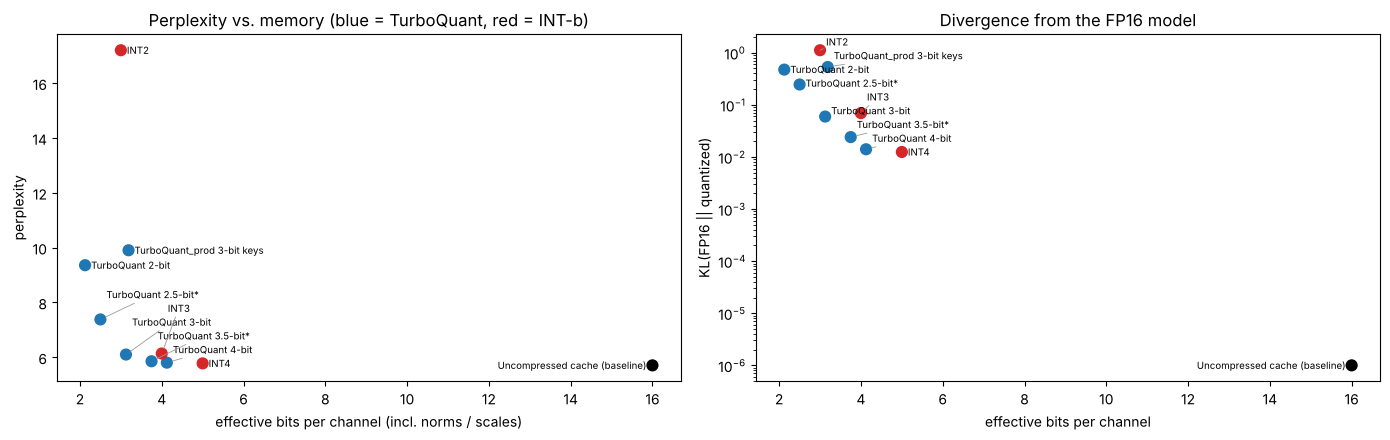

In [8]:
def label_points(ax, xs, ys, labels, fontsize=8, pad=6, gap=2):
    """Write each label next to its point, nudging labels up until none overlap; a thin leader line marks moved ones."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    right_edge = ax.get_window_extent().x1
    placed = []
    for i in np.argsort(pts[:, 1]):
        probe = ax.text(0, 0, labels[i], fontsize=fontsize)
        box = probe.get_window_extent(renderer=renderer)
        probe.remove()
        w, h = box.width, box.height
        left = pts[i, 0] + pad + w > right_edge          # no room on the right: write it on the left
        x0 = pts[i, 0] - pad - w if left else pts[i, 0] + pad
        y0 = pts[i, 1] - h / 2
        moved = True
        while moved:
            moved = False
            for a0, a1, b0, b1 in placed:
                if x0 < a1 and x0 + w > a0 and y0 < b1 + gap and y0 + h + gap > b0:
                    y0, moved = b1 + gap, True
        placed.append((x0, x0 + w, y0, y0 + h))
        dy = y0 + h / 2 - pts[i, 1]
        ax.annotate(labels[i], (xs[i], ys[i]), xytext=(-pad if left else pad, dy), textcoords="offset pixels",
                    fontsize=fontsize, ha="right" if left else "left", va="center",
                    arrowprops=dict(arrowstyle="-", color="0.6", lw=0.6, shrinkA=0, shrinkB=4) if abs(dy) > h / 2 else None)


short = lambda c: c.replace(" (outlier split)", "*").replace(" + scale/zero per 32 ch", "").replace(" (MSE 2b + QJL 1b)", "")
colors = ["C0" if c.startswith("TurboQuant") else ("C3" if c.startswith("INT") else "k") for c in quality.config]
kl = quality.KL_vs_baseline.clip(lower=1e-6)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(quality.bits_per_channel, quality.perplexity, c=colors, s=60, zorder=3)
ax[1].scatter(quality.bits_per_channel, kl, c=colors, s=60, zorder=3)
ax[0].set(xlabel="effective bits per channel (incl. norms / scales)", ylabel="perplexity", title="Perplexity vs. memory (blue = TurboQuant, red = INT-b)")
ax[1].set(xlabel="effective bits per channel", ylabel="KL(FP16 || quantized)", yscale="log", title="Divergence from the FP16 model")
plt.tight_layout()
for a, y in ((ax[0], quality.perplexity), (ax[1], kl)):
    label_points(a, quality.bits_per_channel.to_numpy(), y.to_numpy(), [short(c) for c in quality.config], fontsize=7)
plt.show()

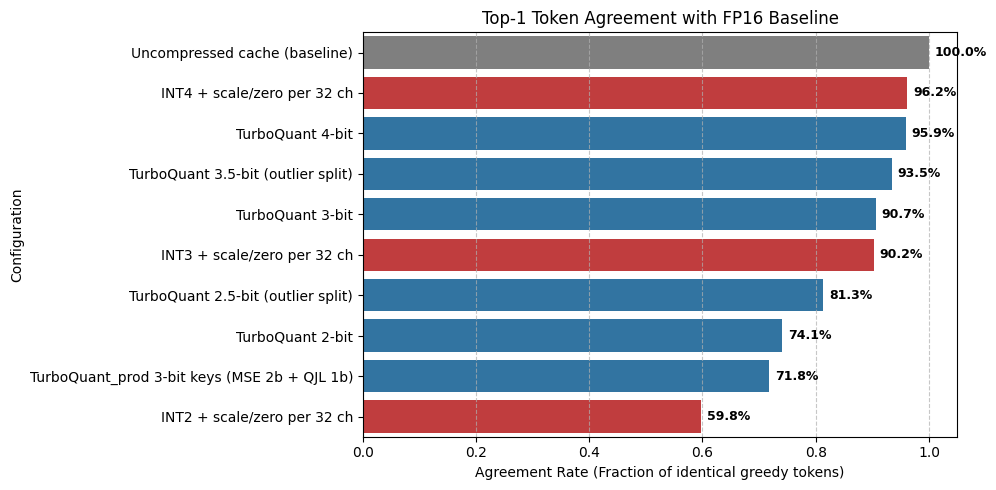

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort results by agreement rate for a clean presentation
df_plot = quality.sort_values(by='top1_agree', ascending=False)

plt.figure(figsize=(10, 5))
colors = ['#1f77b4' if 'TurboQuant' in name else '#d62728' if 'INT' in name else '#7f7f7f' for name in df_plot['config']]

sns.barplot(
    x='top1_agree',
    y='config',
    data=df_plot,
    palette=colors,
    hue='config',
    legend=False
)

plt.title('Top-1 Token Agreement with FP16 Baseline')
plt.xlabel('Agreement Rate (Fraction of identical greedy tokens)')
plt.ylabel('Configuration')
plt.xlim(0, 1.05)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate the exact percentages on the bars
for index, row in enumerate(df_plot.itertuples()):
    plt.text(row.top1_agree + 0.01, index, f"{row.top1_agree * 100:.1f}%", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Explanation of the KV Cache Memory Footprint (Smaller is Better)

This plot compares the physical memory required (`kv_MB`) to store the KV cache of 2048 tokens across configurations on Llama-3.1-8B (32 layers, 8 KV heads, head_dim 128, so 128 KB per token in FP16):

1. **Uncompressed Cache (Baseline)**: **256 MB**.
2. **TurboQuant Savings**: **TurboQuant 4-bit** needs **66 MB** (3.9x smaller), **TurboQuant 2.5-bit** **40 MB** (6.4x) and **TurboQuant 2-bit** **34 MB** (7.5x).
3. **Metadata Overhead**: **INT2 per-group** quantization needs **48 MB**, more than TurboQuant 2.5-bit, because it stores a 16-bit scale and zero point for every group of 32 channels (1 extra bit per channel). TurboQuant's random rotation makes one fixed Lloyd-Max codebook fit every vector, so it stores only one fp16 norm per vector.

These sizes are measured from the packed tensors and do not depend on the text.

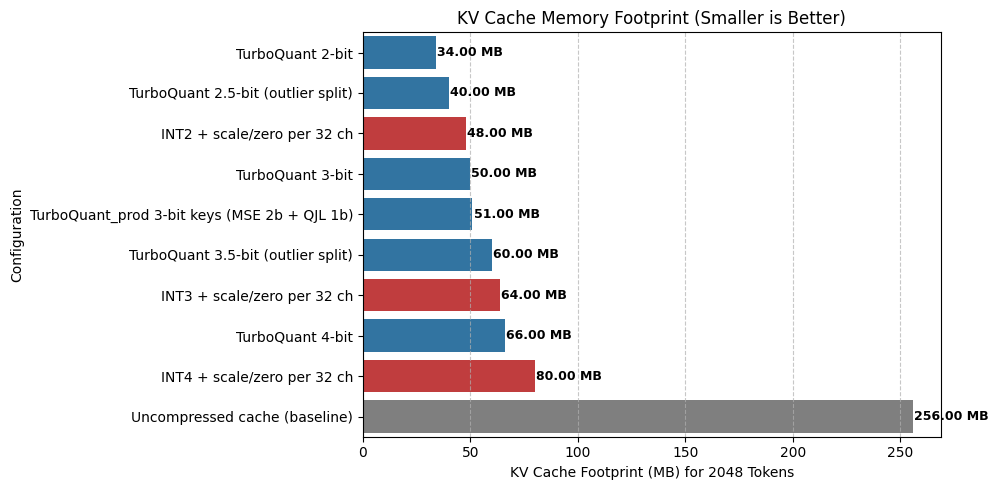

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort results by KV cache size in MB (smaller footprint is better)
df_mem = quality.sort_values(by='kv_MB', ascending=True)

plt.figure(figsize=(10, 5))
colors = ['#1f77b4' if 'TurboQuant' in name else '#d62728' if 'INT' in name else '#7f7f7f' for name in df_mem['config']]

sns.barplot(
    x='kv_MB',
    y='config',
    data=df_mem,
    palette=colors,
    hue='config',
    legend=False
)

plt.title('KV Cache Memory Footprint (Smaller is Better)')
plt.xlabel('KV Cache Footprint (MB) for 2048 Tokens')
plt.ylabel('Configuration')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate the exact MB values on the bars
for index, row in enumerate(df_mem.itertuples()):
    plt.text(row.kv_MB + 0.5, index, f"{row.kv_MB:.2f} MB", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Combined Analysis: Top-1 Agreement vs. Memory Footprint

Below is a combined summary table showing both the accuracy preservation (Top-1 Token Agreement with the FP16 baseline) and the physical memory savings (`kv_MB`) for each KV-cache configuration. This lets you directly inspect which settings achieve the best compression with minimal quality degradation.

In [11]:
# Prepare a combined summary table
combined_df = quality[["config", "bits_per_channel", "compression", "top1_agree", "kv_MB"]].copy()
combined_df["top1_agree_pct"] = (combined_df["top1_agree"] * 100).round(1).astype(str) + "%"
combined_df = combined_df.rename(columns={
    "config": "Configuration",
    "bits_per_channel": "Bits/Channel",
    "compression": "Compression Ratio",
    "top1_agree_pct": "Top-1 Agreement",
    "kv_MB": "Memory (MB)"
}).drop(columns=["top1_agree"])

# Sort by memory footprint (smallest to largest)
combined_df = combined_df.sort_values(by="Memory (MB)", ascending=True).reset_index(drop=True)
display(combined_df)

,Configuration,Bits/Channel,Compression Ratio,Memory (MB),Top-1 Agreement
0,TurboQuant 2-bit,2.125,7.53,34.0,74.1%
1,TurboQuant 2.5-bit (outlier split),2.500,6.40,40.0,81.3%
2,INT2 + scale/zero per 32 ch,3.000,5.33,48.0,59.8%
3,TurboQuant 3-bit,3.125,5.12,50.0,90.7%
4,TurboQuant_prod 3-bit keys (MSE 2b + QJL 1b),3.188,5.02,51.0,71.8%
5,TurboQuant 3.5-bit (outlier split),3.750,4.27,60.0,93.4%
6,INT3 + scale/zero per 32 ch,4.000,4.00,64.0,90.2%
7,TurboQuant 4-bit,4.125,3.88,66.0,95.9%
8,INT4 + scale/zero per 32 ch,5.000,3.20,80.0,96.2%
9,Uncompressed cache (baseline),16.000,1.00,256.0,100.0%


### Memory Footprint vs. Perplexity (Trade-off Curve)

This line plot shows the trade-off between physical KV cache size (`kv_MB`) and perplexity.
* The ideal configuration sits in the **bottom-left** (lowest memory, lowest perplexity).
* Compare points at about the same memory: TurboQuant 3-bit (50 MB) against INT2 (48 MB), and TurboQuant 3.5-bit (60 MB) against INT3 (64 MB).

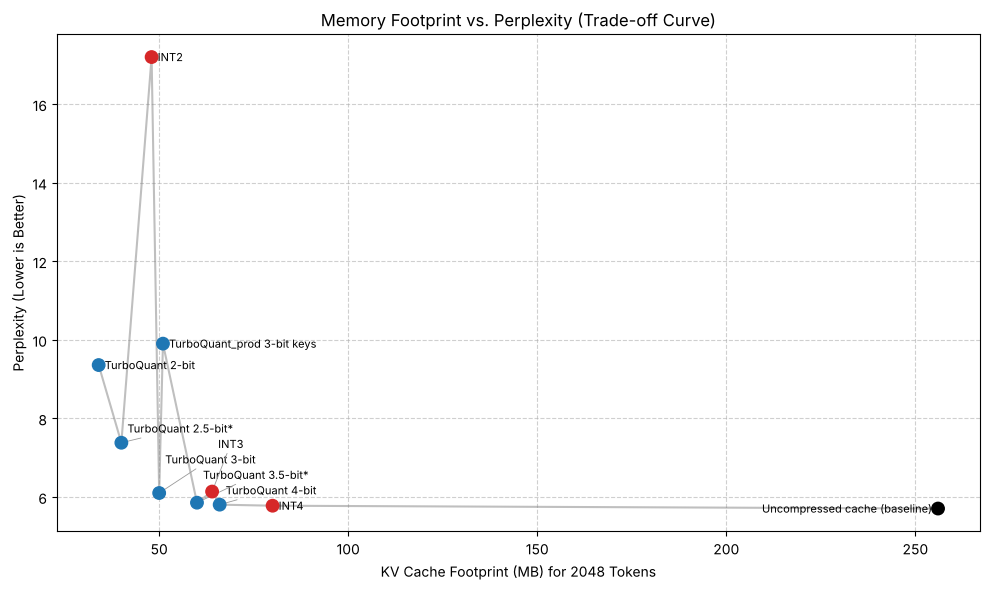

In [12]:
import matplotlib.pyplot as plt

# Sort by memory footprint to make a sensible line/Pareto plot
df_line = quality.sort_values('kv_MB')

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the connected line to show the Pareto curve trend
ax.plot(df_line['kv_MB'], df_line['perplexity'], marker='', linestyle='-', color='gray', alpha=0.5)

# Overlay scatter points with distinct colors
colors = ["#1f77b4" if "TurboQuant" in c else ("#d62728" if "INT" in c else "k") for c in df_line.config]
ax.scatter(df_line.kv_MB, df_line.perplexity, c=colors, s=80, zorder=5)

ax.set_title("Memory Footprint vs. Perplexity (Trade-off Curve)")
ax.set_xlabel("KV Cache Footprint (MB) for 2048 Tokens")
ax.set_ylabel("Perplexity (Lower is Better)")
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Compact labels, spread out so close points stay readable (label_points is defined in the plot cell above)
label_points(ax, df_line.kv_MB.to_numpy(), df_line.perplexity.to_numpy(), [short(c) for c in df_line.config], fontsize=8)
plt.show()

### Correlation Matrix: Quality vs. Memory Metrics

This correlation matrix explores the linear relationships between the metrics collected during the quality evaluation. With only ten configurations it summarises the table above; it is not a statistical test.
* **Bits & Perplexity**: You can observe the strong negative correlation between `bits_per_channel` and `perplexity` (fewer bits lead to higher/worse perplexity).
* **Memory & Agreement**: A high positive correlation between `kv_MB` and `top1_agree` indicates that larger cache footprints preserve the model's exact greedy decisions.

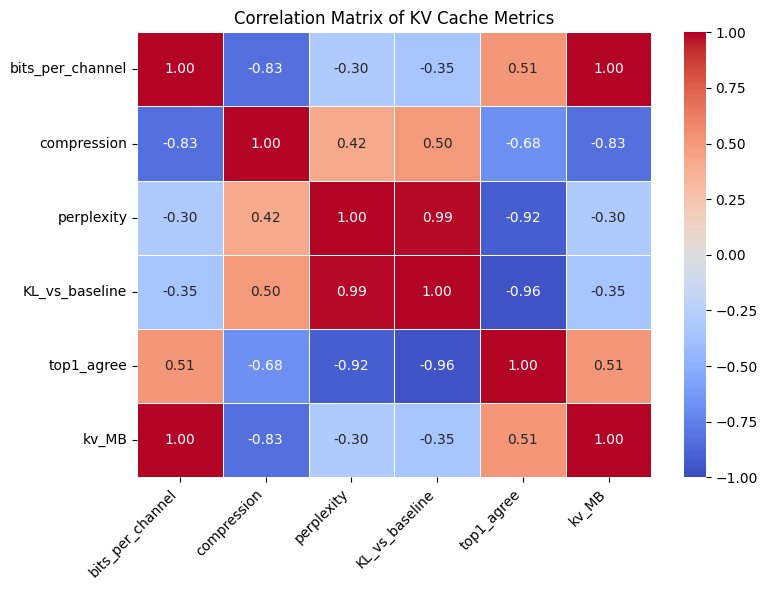

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns for the correlation matrix
numeric_cols = ['bits_per_channel', 'compression', 'perplexity', 'KL_vs_baseline', 'top1_agree', 'kv_MB']
corr_matrix = quality[numeric_cols].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Matrix of KV Cache Metrics")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Explanation of the Needle in a Haystack Task

The "Needle in a Haystack" test is a standard long-context retrieval benchmark used to evaluate how well models can find and extract specific hidden statements (the "needle") within a massive context window of filler text (the "haystack").

1. **Setup**: We inject a secret statement (`NEEDLE = "The secret launch code..."`) at various depths ($0.1, 0.5, 0.9$) inside filler texts of lengths ranging from $2000$ to $8000$ tokens.
2. **Dynamic Generation**: The prompt is processed in a single prefill forward pass, and the KV cache is fully compressed. The model is then asked to output only the secret code.
3. **Evaluation**: A run counts as found only if the exact code appears in the answer. The haystack is the same WikiText-2 text used for the quality section, so the filler is real prose rather than a repeated sentence.

## 4. Needle in a haystack
We hide a fact at different depths of a long filler document, then ask for it. The whole prompt is prefilled once; every answer token is generated while attending to the **compressed** cache.

In [14]:
import importlib
import turboquant_core as tq
importlib.reload(tq)
from turboquant_core import (
    TurboQuant, MixedTurboQuant, UniformQuant, TurboQuantCache, fp16_cache_nbytes,
    tq_factory, mixed_factory, uniform_factory
)

# Re-bind the configurations to the newly reloaded factories
CONFIGS = {
    "Uncompressed cache (baseline)":            None,
    "TurboQuant 4-bit":                 (tq_factory(4), tq_factory(4)),
    "TurboQuant 3.5-bit (outlier split)": (mixed_factory(0.5, 4, 3), mixed_factory(0.5, 4, 3)),
    "TurboQuant 3-bit":                 (tq_factory(3), tq_factory(3)),
    "TurboQuant 2.5-bit (outlier split)": (mixed_factory(0.25, 3, 2), mixed_factory(0.25, 3, 2)),
    "TurboQuant 2-bit":                 (tq_factory(2), tq_factory(2)),
    "TurboQuant_prod 3-bit keys (MSE 2b + QJL 1b)": (tq_factory(3, "prod"), tq_factory(3)),
    "INT4 + scale/zero per 32 ch":      (uniform_factory(4), uniform_factory(4)),
    "INT3 + scale/zero per 32 ch":      (uniform_factory(3), uniform_factory(3)),
    "INT2 + scale/zero per 32 ch":      (uniform_factory(2), uniform_factory(2)),
}

if 'text' not in globals():
    text = ("The history of computing is a story of compression. " * 400)

NEEDLE = "The secret launch code for project Turbo is 7319-ALPHA-42."
QUESTION = "What is the secret launch code for project Turbo? Answer with the code only."
filler_src = text if len(text) > 50000 else (text * 20)

def build_prompt(n_tokens, depth):
    filler_ids = tok(filler_src, return_tensors="pt").input_ids[0, :n_tokens]
    cut = int(len(filler_ids) * depth)
    hay = tok.decode(filler_ids[:cut]) + " " + NEEDLE + " " + tok.decode(filler_ids[cut:])
    msgs = [{"role": "user", "content": f"Read the document and answer the question.\n\n<document>\n{hay}\n</document>\n\n{QUESTION}"}]
    return tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)["input_ids"].to(DEVICE)

@torch.no_grad()
def ask(prompt_ids, cache_name, max_new_tokens=16):
    cache = make_cache(cache_name, residual_length=128)
    out = model.generate(prompt_ids, past_key_values=cache, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, prompt_ids.shape[1]:], skip_special_tokens=True)

LENGTHS = [2000, 4000, 8000] if DEVICE == "cuda" else [500, 1000]
DEPTHS = [0.1, 0.5, 0.9]
NIAH_CONFIGS = ["Uncompressed cache (baseline)", "TurboQuant 4-bit", "TurboQuant 3-bit", "TurboQuant 2.5-bit (outlier split)",
                "TurboQuant 2-bit", "INT2 + scale/zero per 32 ch"]
niah = []
for L in LENGTHS:
    for dep in DEPTHS:
        p = build_prompt(L, dep)
        for name in NIAH_CONFIGS:
            ans = ask(p, name)
            niah.append(dict(config=name, context=p.shape[1], depth=dep, found=int("7319-ALPHA-42" in ans), answer=ans.strip()[:40]))
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
niah = pd.DataFrame(niah)
print(niah.pivot_table(index="config", columns=["context"], values="found", aggfunc="mean").reindex(NIAH_CONFIGS))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


context                                 2084      4083  8084
config                                                      
Uncompressed cache (baseline)       1.000000  1.000000   1.0
TurboQuant 4-bit                    1.000000  1.000000   1.0
TurboQuant 3-bit                    1.000000  1.000000   1.0
TurboQuant 2.5-bit (outlier split)  1.000000  0.333333   1.0
TurboQuant 2-bit                    0.666667  1.000000   1.0
INT2 + scale/zero per 32 ch         0.666667  0.333333   0.0


### Sanity checks on the compressed cache
The next three cells check the cache mechanics rather than the model: concatenating compressed blocks keeps every field aligned, the reconstruction error stays flat as tokens are appended one by one, and the raw answers of three configurations can be read directly.

In [15]:
# Let's run a precise diagnostic on Compressed.cat to see if shapes and scales align correctly during concatenation
import torch
from turboquant_core import Compressed, TurboQuant

d = 128
tq = TurboQuant(d, 4, device=DEVICE)

x1 = torch.randn(1, 2, 10, d, device=DEVICE)
x2 = torch.randn(1, 2, 1, d, device=DEVICE)

c1 = tq.quantize(x1)
c2 = tq.quantize(x2)

try:
    c_cat = c1.cat(c2, dim=2)
    print("Concatenation successful!")
    print("c1.idx shape:", c1.idx.shape)
    print("c2.idx shape:", c2.idx.shape)
    print("c_cat.idx shape:", c_cat.idx.shape)
    print("c1.norm shape:", c1.norm.shape)
    print("c2.norm shape:", c2.norm.shape)
    print("c_cat.norm shape:", c_cat.norm.shape)

    # Test dequantization accuracy after concatenation
    x_dequant = tq.dequantize(c_cat)
    x_orig = torch.cat([x1, x2], dim=2)
    error = (x_orig - x_dequant).abs().mean().item()
    print("Dequantization mean absolute error:", error)
except Exception as e:
    print("Error during concatenation/dequantization check:", e)

Concatenation successful!
c1.idx shape: torch.Size([1, 2, 10, 64])
c2.idx shape: torch.Size([1, 2, 1, 64])
c_cat.idx shape: torch.Size([1, 2, 11, 64])
c1.norm shape: torch.Size([1, 2, 10])
c2.norm shape: torch.Size([1, 2, 1])
c_cat.norm shape: torch.Size([1, 2, 11])
Dequantization mean absolute error: 0.07617288827896118


In [16]:
# Simulation of autoregressive generation using TurboQuantLayer to diagnose cumulative drift
import torch
import numpy as np
from turboquant_core import TurboQuantLayer, tq_factory

# Configure a 4-bit key/value quantizer layer
hd = 128
tq_layer = TurboQuantLayer(tq_factory(4)(0, hd), tq_factory(4)(0, hd), residual_length=128)

# Simulate a prefill of 256 tokens
prefill_k = torch.randn(1, 2, 256, hd, device=DEVICE)
prefill_v = torch.randn(1, 2, 256, hd, device=DEVICE)

tq_layer.lazy_initialization(prefill_k, prefill_v)
k_out, v_out = tq_layer.update(prefill_k, prefill_v)

# Simulate 5 steps of single-token autoregressive generation
steps_k = [torch.randn(1, 2, 1, hd, device=DEVICE) for _ in range(5)]
steps_v = [torch.randn(1, 2, 1, hd, device=DEVICE) for _ in range(5)]

curr_k = prefill_k
curr_v = prefill_v

for i in range(5):
    curr_k = torch.cat([curr_k, steps_k[i]], dim=2)
    curr_v = torch.cat([curr_v, steps_v[i]], dim=2)
    k_dec, v_dec = tq_layer.update(steps_k[i], steps_v[i])

    # Calculate error between fully reconstructed cache and step reference
    err_k = (curr_k - k_dec).abs().mean().item()
    err_v = (curr_v - v_dec).abs().mean().item()
    print(f"Step {i+1} - Cache length: {tq_layer.get_seq_length()} | Key MAE: {err_k:.6f} | Value MAE: {err_v:.6f}")

Step 1 - Cache length: 257 | Key MAE: 0.038872 | Value MAE: 0.038242
Step 2 - Cache length: 258 | Key MAE: 0.039010 | Value MAE: 0.038395
Step 3 - Cache length: 259 | Key MAE: 0.039162 | Value MAE: 0.038566
Step 4 - Cache length: 260 | Key MAE: 0.039286 | Value MAE: 0.038705
Step 5 - Cache length: 261 | Key MAE: 0.039508 | Value MAE: 0.038855


In [17]:
# Inspect the exact generated answers to check if the model is responding close to the needle
p_diag = build_prompt(2000, 0.5)
for name in ["Uncompressed cache (baseline)", "TurboQuant 4-bit", "TurboQuant 2.5-bit (outlier split)"]:
    ans = ask(p_diag, name)
    print(f"[{name}] generated answer:\n{repr(ans)}\n")

[Uncompressed cache (baseline)] generated answer:
'7319-ALPHA-42'

[TurboQuant 4-bit] generated answer:
'7319-ALPHA-42'

[TurboQuant 2.5-bit (outlier split)] generated answer:
'7319-ALPHA-42'



In [18]:
display(niah)

,config,context,depth,found,answer
0,Uncompressed cache (baseline),2084,0.1,1,7319-ALPHA-42
1,TurboQuant 4-bit,2084,0.1,1,7319-ALPHA-42
2,TurboQuant 3-bit,2084,0.1,1,7319-ALPHA-42
3,TurboQuant 2.5-bit (outlier split),2084,0.1,1,7319-ALPHA-42
4,TurboQuant 2-bit,2084,0.1,1,7319-ALPHA-42
5,INT2 + scale/zero per 32 ch,2084,0.1,1,7319-ALPHA-42
6,Uncompressed cache (baseline),2084,0.5,1,7319-ALPHA-42
7,TurboQuant 4-bit,2084,0.5,1,7319-ALPHA-42
8,TurboQuant 3-bit,2084,0.5,1,7319-ALPHA-42
9,TurboQuant 2.5-bit (outlier split),2084,0.5,1,7319-ALPHA-42


### Visualizing Needle in a Haystack Retrieval Accuracy

The heatmap below visualizes the retrieval accuracy of each quantization configuration across different context lengths (averaged across different depth placements of the needle).

* **Values of 1.0 (Dark Blue)** indicate perfect retrieval.
* **Lower values (Light Blue / Yellow)** indicate that the quantization noise caused the model to lose track of the specific long-range attention keys needed to find the hidden code.
* Compare `INT2` (3.0 effective bits per channel, because of its scales) with `TurboQuant 2.5-bit` and `TurboQuant 2-bit`, which use fewer bits. With real text as filler, misses are scattered across lengths and depths rather than tied to the longest context, so read the heatmap together with the per-prompt table above.
* Nine prompts per configuration (three lengths times three depths) is a small sample: read a cell as "found in 3 of 3", "2 of 3", and so on.

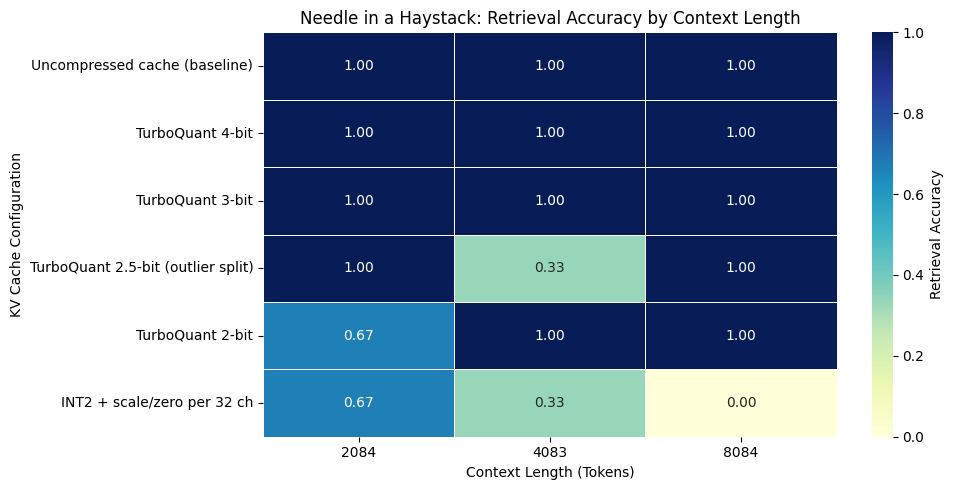

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table for the heatmap: config vs context length (averaged over depths)
heatmap_data = niah.pivot_table(index="config", columns="context", values="found", aggfunc="mean")

# Ensure the rows follow our defined logical order
heatmap_data = heatmap_data.reindex(NIAH_CONFIGS)

# Plot the heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    fmt=".2f",
    linewidths=.5,
    cbar_kws={'label': 'Retrieval Accuracy'}
)

plt.title("Needle in a Haystack: Retrieval Accuracy by Context Length")
plt.ylabel("KV Cache Configuration")
plt.xlabel("Context Length (Tokens)")
plt.tight_layout()
plt.show()

## 5. Memory
First the measured cache size for one long prompt, then the projection for a production-size Llama-3.1-8B model.

### Detailed Explanation: Measuring Physical GPU Memory Footprint

When deploying Large Language Models (LLMs) in production, raw theoretical bit-widths do not always translate to actual memory savings. The code block below directly measures the real physical GPU memory footprint of the Key-Value (KV) cache to demonstrate TurboQuant's memory-saving properties under a long-context scenario (using an 8080-token context prompt).

#### Key Measurement Mechanisms:
1. **Dynamic Evaluation**: We process a long context prompt through the model to build up a substantial KV cache. For each configuration, we reset the PyTorch peak memory allocation tracker (`torch.cuda.reset_peak_memory_stats()`) and clean the garbage collector.
2. **KV Cache Size Calculation (`kv_cache_MB`)**: We calculate the exact size of the cache by analyzing the element size and tensor shapes inside our compressed containers. This corresponds to the physical bytes that must be moved between High-Bandwidth Memory (HBM) and the SRAM of the GPU stream multiprocessors during attention calculations.
3. **Overhead-Free Footprint**: Normal INT-based caches must store scaling factors and zero-point parameters per channel group. This metadata overhead creates a 'tax' that bloats the cache. By removing this requirement, TurboQuant approaches the theoretical lower bound of memory footprints at any target bit rate (e.g., 2-bit or 4-bit).

In [20]:
p = build_prompt(LENGTHS[-1], 0.5)
mem_rows = []
for name in ["Uncompressed cache (baseline)", "TurboQuant 4-bit", "TurboQuant 3.5-bit (outlier split)", "TurboQuant 3-bit",
             "TurboQuant 2.5-bit (outlier split)", "TurboQuant 2-bit", "INT4 + scale/zero per 32 ch", "INT2 + scale/zero per 32 ch"]:
    cache = make_cache(name)
    if DEVICE == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        model(p, past_key_values=cache, use_cache=True)
    mem_rows.append(dict(config=name, tokens=p.shape[1], kv_cache_MB=round(cache_nbytes(cache) / 2 ** 20, 2),
                         bits_per_channel=round(bits_per_channel(cache, p.shape[1]), 3),
                         peak_gpu_MB=round(torch.cuda.max_memory_allocated() / 2 ** 20) if DEVICE == "cuda" else None))
    del cache; gc.collect()
mem = pd.DataFrame(mem_rows)
mem["vs_baseline"] = (mem.kv_cache_MB[0] / mem.kv_cache_MB).round(2).astype(str) + "x smaller"
display(mem)

,config,tokens,kv_cache_MB,bits_per_channel,peak_gpu_MB,vs_baseline
0,Uncompressed cache (baseline),8084,1010.50,16.000,22691,1.0x smaller
1,TurboQuant 4-bit,8084,260.52,4.125,22956,3.88x smaller
2,TurboQuant 3.5-bit (outlier split),8084,236.84,3.750,22946,4.27x smaller
3,TurboQuant 3-bit,8084,197.36,3.125,22893,5.12x smaller
4,TurboQuant 2.5-bit (outlier split),8084,157.89,2.500,22862,6.4x smaller
5,TurboQuant 2-bit,8084,134.21,2.125,22830,7.53x smaller
6,INT4 + scale/zero per 32 ch,8084,315.78,5.000,23006,3.2x smaller
7,INT2 + scale/zero per 32 ch,8084,189.47,3.000,22882,5.33x smaller


In [21]:
# What it means for Llama-3.1-8B (32 layers, 8 KV heads, head_dim 128) on a 24 GB GPU after 16 GB of weights.
L_, H_, D_ = 32, 8, 128
def per_token_bytes(bits, norm_bits=16):
    return 2 * L_ * H_ * (bits * D_ + norm_bits) / 8
budget = 8 * 2 ** 30
proj = []
for label, bits, extra in [("FP16", 16, 0), ("INT4 + scale/zero (g=32)", 4, 32 * D_ // 32), ("TurboQuant 4-bit", 4, 16),
                           ("TurboQuant 3.5-bit", 3.5, 32), ("TurboQuant 2.5-bit", 2.5, 32)]:
    b = per_token_bytes(bits, extra)
    proj.append(dict(cache=label, KB_per_token=round(b / 1024, 1), max_context_in_8GB=int(budget / b)))
print(pd.DataFrame(proj).to_string(index=False))

                   cache  KB_per_token  max_context_in_8GB
                    FP16         128.0               65536
INT4 + scale/zero (g=32)          40.0              209715
        TurboQuant 4-bit          33.0              254200
      TurboQuant 3.5-bit          30.0              279620
      TurboQuant 2.5-bit          22.0              381300


## 6. Speed (and why fused kernels matter)
The reference cache dequantizes the whole history every step in PyTorch, so it **adds** latency. TurboQuant's speed claims (up to 8x faster attention logits at 4 bits on H100 in Google's blog) come from kernels that compute attention directly from the packed codes: the GPU reads 4x fewer bytes from HBM, and decode attention is memory-bound.

In [22]:
@torch.no_grad()
def decode_speed(name, prompt, n_new=64):
    cache = make_cache(name)
    model(prompt[:, :-1], past_key_values=cache, use_cache=True)
    nxt = prompt[:, -1:]
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(n_new):
        logits = model(nxt, past_key_values=cache, use_cache=True).logits
        nxt = logits[:, -1:].argmax(-1)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return n_new / (time.time() - t)

p = build_prompt(LENGTHS[1], 0.5)
for name in ["Uncompressed cache (baseline)", "TurboQuant 4-bit", "TurboQuant 2.5-bit (outlier split)"]:
    print(f"{name:40s} {decode_speed(name, p):6.1f} tok/s  (context {p.shape[1]})")

Uncompressed cache (baseline)              26.3 tok/s  (context 4083)
TurboQuant 4-bit                           10.2 tok/s  (context 4083)
TurboQuant 2.5-bit (outlier split)          6.5 tok/s  (context 4083)


### Production path: vLLM
vLLM (0.20.2+) ships fused TurboQuant kernels. On an Ampere/Hopper GPU:
```bash
pip install -U vllm
vllm serve meta-llama/Llama-3.1-8B-Instruct --kv-cache-dtype turboquant_4bit_nc   # also: turboquant_k8v4, turboquant_k3v4_nc, turboquant_3bit_nc
```
vLLM's blog reports 2.3-3.7x more KV-cache capacity, at 66-80% of BF16 throughput, with the aggressive 3-bit variants losing accuracy on hard reasoning tasks. FP8 remains the throughput-neutral option.

### Takeaways
* The rotation makes every coordinate follow the same known distribution, so one precomputed codebook works for any data, with no calibration and no per-block scales.
* At ~4 bits TurboQuant is close to lossless; 3.5 and 2.5 bits with outlier channels are the paper's sweet spots.
* At the same total bits, uniform INT-b pays ~1 extra bit per channel for scales and zero points.
* `TurboQuant_prod` is unbiased, but its QJL variance hurts softmax attention at low bits, which is why most implementations use the MSE variant (plus norm correction) for KV caches.